# EDA inicial del dataset de Airbnb Barcelona

Este notebook corresponde a la issue #6. Se exploran los datos originales de `listings.csv.gz` sin aplicar todavía la limpieza ni el feature engineering de las issues #7–#9.

Objetivos:
- comprobar estructura, tipos y tamaño del dataset;
- localizar valores nulos y columnas completamente vacías;
- observar las distribuciones de las variables principales;
- detectar posibles outliers mediante el criterio IQR.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep", context="notebook", font_scale=1.25)
plt.rcParams.update({"axes.titlesize": 15, "axes.labelsize": 13, "xtick.labelsize": 11, "ytick.labelsize": 11})
pd.set_option("display.max_columns", 100)
DATA_PATH = Path("../data/raw/listings.csv.gz")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"No se encuentra {DATA_PATH}. Descarga listings.csv.gz en data/raw/."
    )

df = pd.read_csv(DATA_PATH, compression="gzip")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]:,}")
display(df.head(3))

Filas: 15,236
Columnas: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,18674,https://www.airbnb.com/rooms/18674,20260917041147,2026-09-18,NaN,Huge flat for 8 people close to Sagrada Familia,"* Currently, facade works are being carried ou...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,71615,https://www.airbnb.com/users/show/71615,1462508358342835057,https://www.airbnb.com/users/profile/146250835...,Maria Y Mireia Y Ana Barcelona4Seasons,NaN,16.0,7.0,15.0,8.0,"Barcelona, Spain","We are Mireia and Maria, two multilingual entr...",NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/User/...,NaN,32,NaN,NaN,t,t,NaN,la Sagrada Família,Eixample,41.40556,2.17262,Entire rental unit,Entire home/apt,8,NaN,2 baths,3.0,5.0,"[""Toaster"", ""AC - split type ductless system"",...",$274.00,2026-09-23,2026-09-25,548.0,274.00,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""...",1.0,999.0,1.0,4.0,999.0,999.0,3.4,999.0,NaN,t,12,36,62,162,2026-09-18,60,8,0,77,9,48,13152.0,2013-05-27,2026-07-20,4.42,4.47,4.59,4.66,4.63,4.81,4.37,Spain - National registration number<br />ESFC...,NaN,21,21,0,0,0.37
1,23197,https://www.airbnb.com/rooms/23197,20260917041147,2026-09-18,NaN,CCIB Forum • Spacious 3BR • Large Balcony,"Beautiful, spacious apartment with large balco...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,90417,https://www.airbnb.com/users/show/90417,1462509351463595774,https://www.airbnb.com/users/profile/146250935...,Marnie,NaN,16.0,6.0,15.0,8.0,"Catalonia, Spain","Hi there,\n\nI’m marnie, originally from Austr...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/44b56...,NaN,5,NaN,NaN,t,t,NaN,el Besòs i el Maresme,Sant Martí,41.41243,2.21975,Entire rental unit,Entire home/apt,5,NaN,2 baths,3.0,4.0,"[""Toaster"", ""Portable heater"", ""AC - split typ...",$407.67,2026-09-20,2026-09-23,1223.0,407.67,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""...",3.0,1125.0,3.0,4.0,1125.0,1125.0,3.0,1125.0,NaN,t,23,44,74,128,2026-09-18,102,11,2,89,11,66,26906.0,2011-03-15,2026-09-07,4.84,4.95,4.91,4.94,4.99,4.70,4.72,Spain - National registration number<br />ESFC...,NaN,1,1,0,0,0.54
2,34981,https://www.airbnb.com/rooms/34981,20260917041147,2026-09-18,NaN,VIDRE HOME PLAZA REAL on LAS RAMBLAS,Spacious apartment for large families or group...,NaN,https://a0.muscache.com/pictures/c4d1723c-e479...,73163,https://www.airbnb.com/users/show/73163,146250

## 1. Estructura y tipos de datos

In [2]:
structure = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "nulls": df.isna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
}).sort_values(["null_pct", "unique"], ascending=[False, True])
display(structure)
print(f"Filas duplicadas completas: {df.duplicated().sum():,}")
print(f"Columnas completamente nulas: {(df.isna().all()).sum()}")
display(df.columns.to_frame(index=False, name="column"))

,dtype,non_null,nulls,null_pct,unique
neighborhood_overview,float64,0,15236,100.0,0
host_since,float64,0,15236,100.0,0
host_response_time,float64,0,15236,100.0,0
host_response_rate,float64,0,15236,100.0,0
host_acceptance_rate,float64,0,15236,100.0,0
...,...,...,...,...,...
amenities,str,15236,0,0.0,11741
name,str,15236,0,0.0,14387
picture_url,str,15236,0,0.0,15116
id,int64,15236,0,0.0,15236


Filas duplicadas completas: 0
Columnas completamente nulas: 13


,column
0,id
1,listing_url
2,scrape_id
3,last_scraped
4,source
...,...
85,calculated_host_listings_count
86,calculated_host_listings_count_entire_homes
87,calculated_host_listings_count_private_rooms
88,calculated_host_listings_count_shared_rooms


## 2. Valores nulos

,null_count,null_pct
host_acceptance_rate,15236,100.00
host_thumbnail_url,15236,100.00
neighborhood_overview,15236,100.00
host_since,15236,100.00
instant_bookable,15236,100.00
bathrooms,15236,100.00
neighbourhood,15236,100.00
host_verifications,15236,100.00
host_total_listings_count,15236,100.00
host_neighbourhood,15236,100.00


,null_count,null_pct,note
price,2626,17.24,Incluida explícitamente por ser la variable ob...


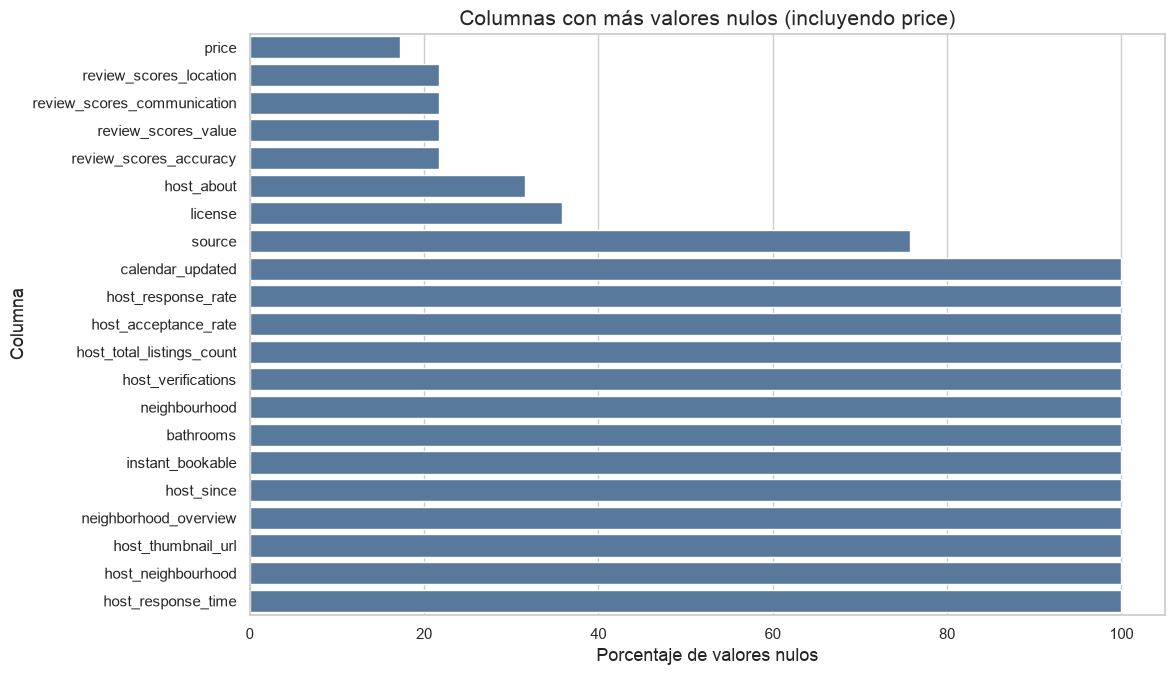

In [3]:
missing = (
    df.isna().sum().rename("null_count").to_frame()
    .assign(null_pct=lambda x: (x["null_count"] / len(df) * 100).round(2))
    .query("null_count > 0")
    .sort_values("null_pct", ascending=False)
)
display(missing.head(25))
if "price" in missing.index and "price" not in missing.head(25).index:
    display(missing.loc[["price"]].assign(note="Incluida explícitamente por ser la variable objetivo"))

plt.figure(figsize=(12, 7))
plot_columns = list(missing.head(20).index)
if "price" in missing.index and "price" not in plot_columns:
    plot_columns.append("price")
plot_missing = missing.loc[plot_columns].sort_values("null_pct")
sns.barplot(data=plot_missing, x="null_pct", y=plot_missing.index, color="#4C78A8")
plt.xlabel("Porcentaje de valores nulos")
plt.ylabel("Columna")
plt.title("Columnas con más valores nulos (incluyendo price)")
plt.tight_layout()
plt.show()

## 3. Distribución de variables principales

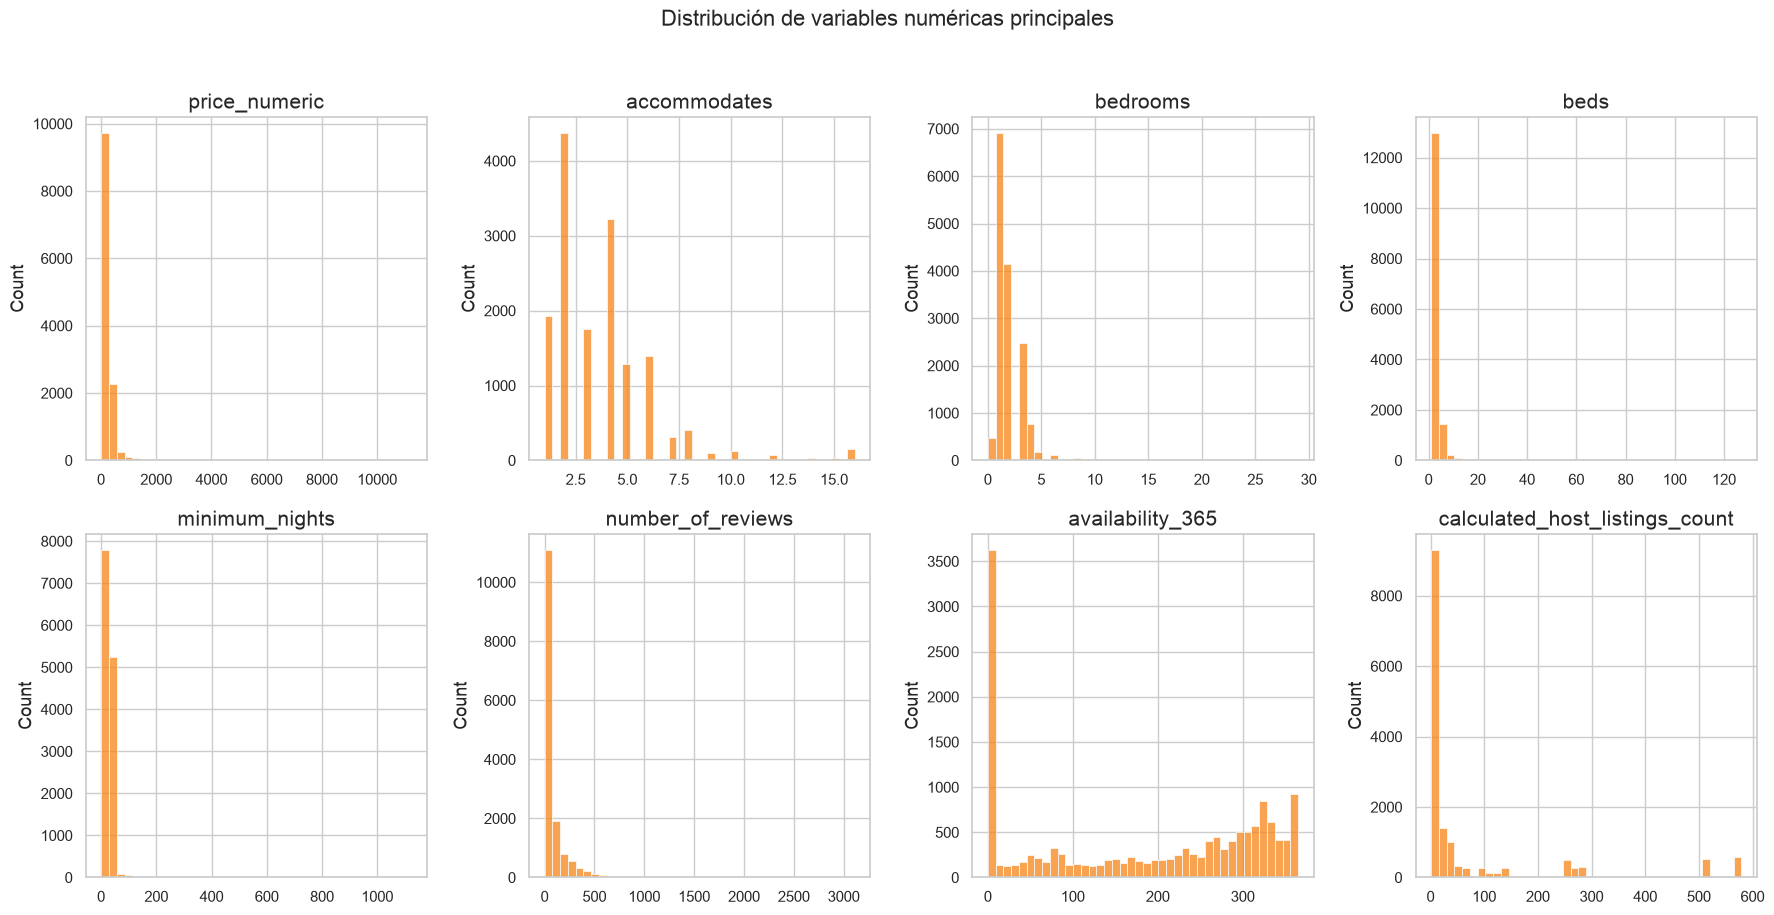

,count,mean,std,min,25%,50%,75%,max
price_numeric,12610.0,253.41433,386.336426,12.81,93.385,190.67,284.0,11245.03
accommodates,15236.0,3.672092,2.485188,1.0,2.0,3.0,5.0,16.0
bedrooms,15234.0,1.911382,1.478047,0.0,1.0,2.0,2.0,29.0
beds,14822.0,2.692349,2.547771,1.0,1.0,2.0,3.0,127.0
minimum_nights,13191.0,15.292017,25.039049,1.0,1.0,3.0,31.0,1124.0
number_of_reviews,15236.0,73.985823,139.775535,0.0,1.0,13.0,93.0,3111.0
availability_365,15236.0,180.478866,135.103253,0.0,23.0,210.0,310.0,365.0
calculated_host_listings_count,15236.0,73.961538,150.059,1.0,2.0,9.0,40.0,579.0


In [4]:
# Se convierte price solo para esta exploración; la limpieza definitiva corresponde a #7.
eda = df.copy()
eda["price_numeric"] = (
    eda["price"].astype("string").str.replace(r"[$,]", "", regex=True)
    .pipe(pd.to_numeric, errors="coerce")
)

distribution_columns = [
    "price_numeric", "accommodates", "bedrooms", "beds",
    "minimum_nights", "number_of_reviews", "availability_365",
    "calculated_host_listings_count",
]
available = [column for column in distribution_columns if column in eda.columns]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, column in zip(axes.flat, available):
    sns.histplot(eda[column].dropna(), bins=40, ax=ax, color="#F58518")
    ax.set_title(column)
    ax.set_xlabel("")
for ax in axes.flat[len(available):]:
    ax.set_visible(False)
fig.suptitle("Distribución de variables numéricas principales", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

display(eda[available].describe().T.round(2))

## 4. Variables potencialmente relacionadas con el precio

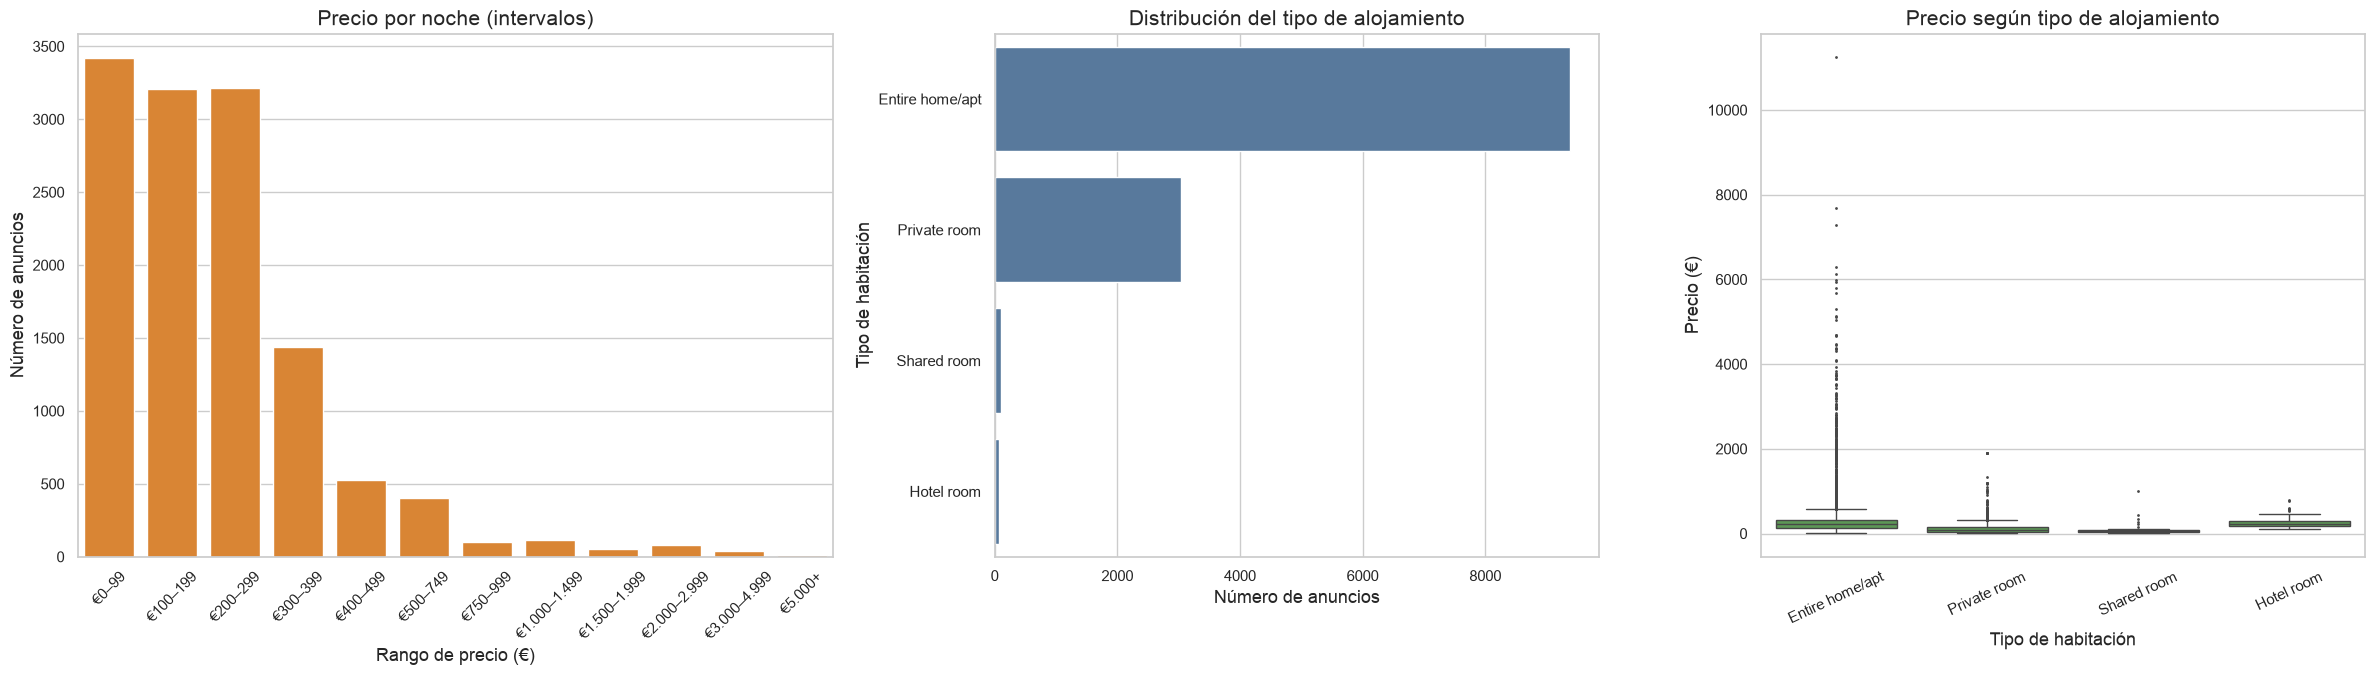

,count,median,mean,min,max
room_type,,,,,
Hotel room,71,228.0,275.97,99.9,800.0
Entire home/apt,9386,222.53,298.54,18.72,11245.03
Private room,3043,72.68,120.1,12.81,1900.0
Shared room,110,53.0,76.83,19.53,1000.0


In [5]:
# Estas visualizaciones son exploratorias: muestran asociaciones, no causalidad.
room_price = eda.dropna(subset=["price_numeric", "room_type"]).copy()
fig, axes = plt.subplots(1, 3, figsize=(24, 7), gridspec_kw={"width_ratios": [1.25, 1, 1]})

price_bins = [0, 100, 200, 300, 400, 500, 750, 1000, 1500, 2000, 3000, 5000, np.inf]
price_labels = ["€0–99", "€100–199", "€200–299", "€300–399", "€400–499", "€500–749", "€750–999", "€1.000–1.499", "€1.500–1.999", "€2.000–2.999", "€3.000–4.999", "€5.000+"]
price_values = eda["price_numeric"]
price_bucket = pd.cut(price_values, bins=price_bins, labels=price_labels, right=False)
price_counts = price_bucket.value_counts(sort=False).reindex(price_labels, fill_value=0)
sns.barplot(x=price_counts.index, y=price_counts.values, ax=axes[0], color="#F58518", edgecolor="white")
axes[0].set_title("Precio por noche (intervalos)")
axes[0].set_xlabel("Rango de precio (€)")
axes[0].set_ylabel("Número de anuncios")
axes[0].tick_params(axis="x", rotation=45, labelsize=11)

room_order = room_price["room_type"].value_counts().index
sns.countplot(data=room_price, y="room_type", order=room_order, ax=axes[1], color="#4C78A8")
axes[1].set_title("Distribución del tipo de alojamiento")
axes[1].set_xlabel("Número de anuncios")
axes[1].set_ylabel("Tipo de habitación")

sns.boxplot(data=room_price, x="room_type", y="price_numeric", order=room_order, ax=axes[2], color="#54A24B", fliersize=1)
axes[2].set_title("Precio según tipo de alojamiento")
axes[2].set_xlabel("Tipo de habitación")
axes[2].set_ylabel("Precio (€)")
axes[2].tick_params(axis="x", rotation=25, labelsize=11)

plt.tight_layout()
plt.show()

display(
    room_price.groupby("room_type", observed=True)["price_numeric"]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_values("median", ascending=False)
    .round(2)
)

### Lectura exploratoria

El precio presenta una distribución asimétrica y `room_type` muestra grupos con tamaños y precios diferentes. Esta variable puede aportar información para clasificar el segmento de precio, pero la relación debe evaluarse posteriormente con el target en tres clases, el preprocesamiento y los modelos. Los valores extremos y los precios ausentes se tratarán en las issues #7 y #12.

## 5. Detección exploratoria de outliers

,q1,q3,lower_bound,upper_bound,outlier_count,outlier_pct
column,,,,,,
calculated_host_listings_count,2.00,40.0,-55.00,97.00,2679,17.58
number_of_reviews,1.00,93.0,-137.00,231.00,1479,9.71
bedrooms,1.00,2.0,-0.50,3.50,1232,8.09
price_numeric,93.38,284.0,-192.54,569.92,635,5.04
beds,1.00,3.0,-2.00,6.00,634,4.16
accommodates,2.00,5.0,-2.50,9.50,454,2.98
minimum_nights,1.00,31.0,-44.00,76.00,103,0.68
availability_365,23.00,310.0,-407.50,740.50,0,0.00


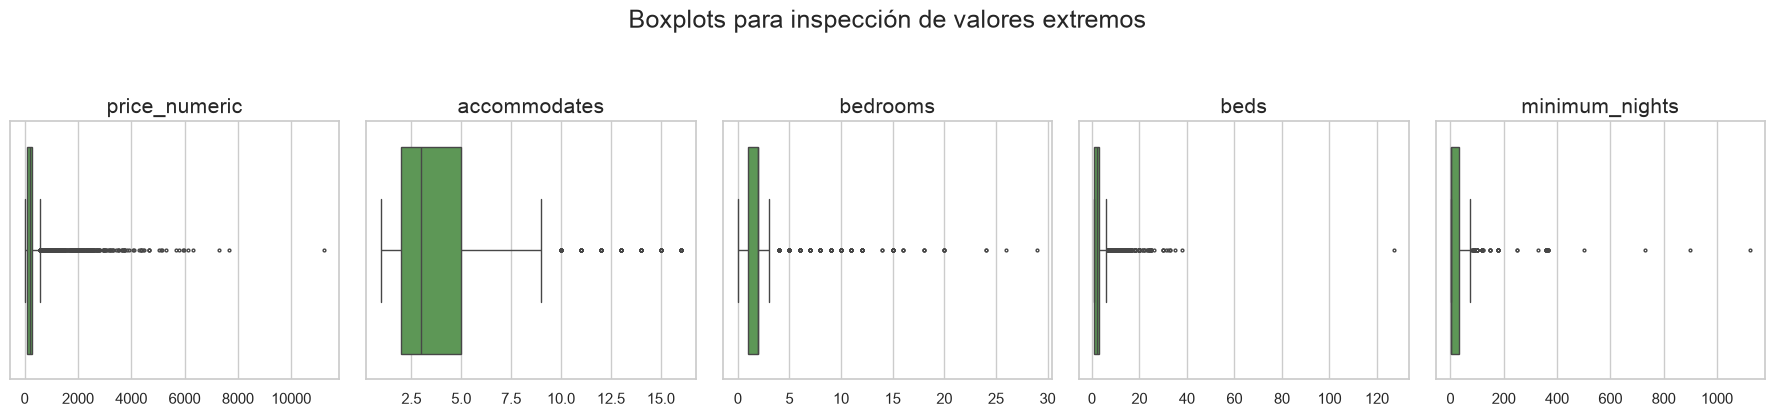

In [6]:
outlier_columns = [column for column in available if eda[column].notna().any()]
outlier_rows = []
for column in outlier_columns:
    values = eda[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (eda[column] < lower) | (eda[column] > upper)
    outlier_rows.append({
        "column": column, "q1": q1, "q3": q3,
        "lower_bound": lower, "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": round(mask.mean() * 100, 2),
    })
outliers = pd.DataFrame(outlier_rows).set_index("column")
display(outliers.sort_values("outlier_pct", ascending=False).round(2))

box_columns = [column for column in ["price_numeric", "accommodates", "bedrooms", "beds", "minimum_nights"] if column in eda]
fig, axes = plt.subplots(1, len(box_columns), figsize=(18, 4))
for ax, column in zip(np.atleast_1d(axes), box_columns):
    sns.boxplot(x=eda[column], ax=ax, color="#54A24B", fliersize=2)
    ax.set_title(column)
    ax.set_xlabel("")
plt.suptitle("Boxplots para inspección de valores extremos", y=1.05)
plt.tight_layout()
plt.show()

## Conclusiones iniciales

- El dataset contiene muchas columnas con ausencia total o elevada de datos; deben revisarse antes del modelado.
- `price` llega como texto con símbolo monetario y se ha convertido únicamente en una copia exploratoria (`price_numeric`).
- Las variables de precio y noches mínimas presentan colas y valores extremos que deberán tratarse en la issue #7.
- Las decisiones definitivas sobre eliminación de columnas, outliers y variables derivadas se documentarán en las issues #7–#9; este notebook no modifica el dataset original.